# Latent Feature Extraction for Musical Genres from Raw Audio
## Source-grounded reproduction, measured results, and discrepancy audit

**Paper:** Arjun Sawhney, Vrinda Vasavada, Woody Wang (2018), supplied `mini_project.pdf`.
**Reference implementation:** [Genre-Extraction](https://github.com/arjunsawknee/Genre-Extraction/tree/00b1802e24d1ab6fb3135b24a44976a51033ed24), pinned commit `00b1802e24d1ab6fb3135b24a44976a51033ed24`.

This notebook contains the complete implementation and follows the paper's experimental progression:
raw-input PCA → two-layer classifier → unsupervised deep autoencoder → joint autoencoder/classifier
→ accuracy, precision/recall/F1 and confusion matrix → 64-D and 4-D embedding PCA.

**Read the comparison labels carefully.** The PDF and released code disagree on loss scaling,
dropout and training duration. It is impossible to implement both conflicting definitions as one
"exact" experiment. We therefore run a released-code version, a paper architecture/schedule version
with the repository loss, and a literal PDF-equation version. All measured scores come from saved
predictions; the paper's reference scores are never used as model outputs or training targets.

The paper's original seed, file enumeration order and final 1,000/1,000 development/test assignment
are unavailable. Our fixed seed is 42, with the segment membership saved to CSV. Consequently,
numerical equality with the paper is not guaranteed, even when the architecture agrees.

### What the supplied materials establish

The first notebook's saved test accuracies are **47.5% baseline** and **42.3% joint model**.
It resamples to 20 kHz, chooses random segments from whole recordings, uses different nonlinearities,
and applies a summed reconstruction error. Those are substantial differences from the linked code.

The initial ablation file has no saved outputs. The subsequently supplied **`abalation.ipynb`**
contains partial results through its deep learning-rate/epoch grid, despite cleared execution-count
fields. Its cell source matches the initial ablation file. Its measurements are incorporated below;
they are development-set results, not completed held-out test evaluations.

| Item | PDF | Released code | This notebook |
|---|---|---|---|
| Genres | classical, jazz, pop, metal | label order classical, jazz, metal, pop | repository label order everywhere |
| Dataset | 8,000 balanced examples | first 20 chunks per song | 100 songs × 20 chunks × 4 genres |
| Segment size | calls 20,000 samples one second at 22.05 kHz | 20,000 native samples | 0.9070 s; no 20 kHz resampling |
| Pooling | mean, width 40 → 500-D | same | same, with exact source comparisons |
| Split | 6,000 / 1,000 / 1,000 | 6,000 / 2,000 | PDF sizes; seeded random segment split |
| Baseline | 500 → 128(tanh) → 4 | Adam 1e-4, 200 epochs, batch 512 | repository settings |
| Encoder | 500 → 256 → 192 → 128 → 64 | sigmoid, tanh, ReLU, ReLU | exact released activations |
| Decoder | 64 → 128 → 192 → 256 → 500 | sigmoid, sigmoid, ReLU, ReLU | exact released activations |
| Head | 64 → 32 → 16 → 4 | tanh, tanh, linear logits | same |
| Dropout | keep 0.9 | keep 0.8 after encoder 192 and decoder 192 | both, in separate runs |
| Joint loss | 0.9 × sum-squared-error + 0.1 × CE | mean-squared-error + 0.1 × CE | both, in separate runs |
| Duration | Figure 3 shows 500 epochs | joint/baseline 200, vanilla 400 | all durations explicitly recorded |
| Initialization | unspecified | Xavier uniform, zero biases | same distribution; different framework RNG |
| Shuffle | random split | training order shuffled once | seeded split + one train-only shuffle |

With 500 inputs, the PDF's loss gives reconstruction **4,500 times the relative weight** used by the
repository. No pretraining, input normalization, MFCCs, spectrograms or pretrained audio network is added.
The vanilla autoencoder is trained on the training subset only; its released script instead fits all 8,000 examples.

### What the partial ablation run actually shows

The added `abalation.ipynb` supplies development results, with later cells still unfinished:

| Completed check | Observed result | Interpretation |
|---|---|---|
| Preprocessing/selection screening | best baseline dev 52.2% | Changing segment selection alone did not close the gap |
| Baseline LR/epoch/batch screening | final dev 54.7%; best observed epoch 55.6% | Stronger baseline uses LR 1e-3, batch 16, 100 epochs; differs from repository schedule |
| Unsupervised AE + trained linear probe | best probe dev 60.5% | ReLU/tanh bottleneck, LR 3e-4, dropout 0.05, 100 epochs; not the joint classifier |
| Joint loss at gamma=0.9 | sum: 38.8%; mean: 52.3% dev | Reconstruction scaling materially affects this tanh architecture |
| Joint classification-only gamma=0 | 55.4% dev | Turning reconstruction off helps this implementation, but changes the proposed method |
| Partially completed joint LR/epoch grid | largest printed dev 59.7% | LR 3e-4, 200 epochs; no completed final test evaluation is saved |

The source's mixed sigmoid/tanh/ReLU architecture is absent from that sweep. This motivates the
source-grounded models below, rather than selecting another generic tanh variant. The partial
ablation's best-reconstruction selector compares raw `sum` and `mean` losses across rows; those
values differ by 500 and should not be ranked together. The original outputs remain untouched;
the accompanying extractor saves the explicitly printed measurements as CSV files.

### Run instructions

Run all cells in this notebook using the project `.venv` kernel, or upload this notebook alone to
Google Colab and select a GPU runtime. Dependencies are installed only when absent. The first run
downloads a 1.23 GB GTZAN archive; later runs reuse it. Results persist under `results/`.
Set `WORK_DIR` to a Google Drive folder before running if you need persistence across Colab sessions.

`SMOKE=True` is only a two-epoch software check and is never presented as a paper reproduction.
By default the notebook runs all five main experiments, two additional initialization seeds and
a separate song-disjoint experiment. Checkpoints are reused only when configuration, implementation,
data, split and framework fingerprints agree. Delete a run's `completed.json` to force retraining.

In [1]:
import importlib.util
import os
import subprocess
import sys
from pathlib import Path

os.environ.setdefault('CUBLAS_WORKSPACE_CONFIG', ':4096:8')
os.environ.setdefault('MPLBACKEND', 'Agg')
dependencies = {'numpy':'numpy', 'pandas':'pandas', 'scipy':'scipy',
                'sklearn':'scikit-learn', 'matplotlib':'matplotlib', 'soundfile':'soundfile',
                'requests':'requests', 'torch':'torch'}
missing = [package for module,package in dependencies.items() if importlib.util.find_spec(module) is None]
if missing:
    subprocess.check_call([sys.executable, '-m', 'pip', 'install', *missing])

WORK_DIR = Path.cwd()  # In Colab optionally set this to your mounted Drive directory.
WORK_DIR.mkdir(parents=True, exist_ok=True)
os.chdir(WORK_DIR)
RESULT_DIR = WORK_DIR / 'results' / 'source_grounded'
SMOKE = False
RUN_SEED_ROBUSTNESS = True
RUN_SONG_DISJOINT = True

In [2]:
EMBEDDED_IMPLEMENTATION_SHA256 = '4b1853593bce0fa1a05f6a2b10eaf3b46d018ce089dc2c58f061347660ac11b2'

### Imports and reproducibility helpers

In [3]:
import copy
import hashlib
import json
import math
import os
import platform
import random
import subprocess
import sys
import tarfile
import time
from dataclasses import asdict, dataclass
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import requests
import soundfile as sf
import torch
from sklearn.decomposition import PCA
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
from sklearn.model_selection import train_test_split
from torch import nn
from torch.nn import functional as F

GENRES = ['classical', 'jazz', 'metal', 'pop']  # Original repository order.
SOURCE_COMMIT = '00b1802e24d1ab6fb3135b24a44976a51033ed24'
DATA_URL = 'https://huggingface.co/datasets/marsyas/gtzan/resolve/main/data/genres.tar.gz'
DATA_SHA256 = 'b28cc067ff6199bd826f5d1a6931458586d64acae7f44b2e882b7a97af057531'
HEADERLESS_JAZZ_SHA256 = 'eb8be6097ee1f32965fb9545cb1621b4685e4b0d44c6584cf0ab97d244ad535f'
DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
torch.set_num_threads(min(4, os.cpu_count() or 1))


def sha256(path):
    h = hashlib.sha256()
    with Path(path).open('rb') as f:
        for block in iter(lambda: f.read(4 * 1024 * 1024), b''):
            h.update(block)
    return h.hexdigest()


def seed_everything(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)
    # No TF32 or mixed precision: these tiny networks do not need it.
    if torch.cuda.is_available():
        torch.backends.cuda.matmul.allow_tf32 = False
        torch.backends.cudnn.allow_tf32 = False
    torch.use_deterministic_algorithms(True)

### Dataset download, pooling and split manifests

In [4]:
def download_data(root=Path('data')):
    """Use the pinned Marsyas archive mirror; audit its damaged jazz WAV explicitly."""
    root = Path(root)
    root.mkdir(parents=True, exist_ok=True)
    archive = root / 'genres.tar.gz'
    if not archive.exists():
        temporary = archive.with_suffix('.part')
        with requests.get(DATA_URL, stream=True, timeout=(30, 120)) as response:
            response.raise_for_status()
            total = 0
            with temporary.open('wb') as f:
                for block in response.iter_content(4 * 1024 * 1024):
                    f.write(block)
                    total += len(block)
                    if total // (200 * 1024 * 1024) != (total-len(block)) // (200 * 1024 * 1024):
                        print(f'Downloaded {total / 1e6:.0f} MB', flush=True)
        temporary.replace(archive)
    if sha256(archive) != DATA_SHA256:
        raise ValueError('The GTZAN archive checksum does not match the pinned source.')
    target = (root / 'original').resolve()
    with tarfile.open(archive) as tar:
        for member in tar.getmembers():
            if (not member.isfile() or not member.name.endswith(('.au', '.wav'))
                    or Path(member.name).name.startswith('._')):
                continue
            if not any('/' + genre + '/' in member.name for genre in GENRES):
                continue
            dest = (target / member.name).resolve()
            if not dest.is_relative_to(target):
                raise ValueError(f'Unsafe archive path: {member.name}')
            dest.parent.mkdir(parents=True, exist_ok=True)
            if not dest.exists():
                with tar.extractfile(member) as src, dest.open('wb') as dst:
                    dst.write(src.read())
    candidates = [p for p in target.rglob('genres') if all((p / g).is_dir() for g in GENRES)]
    if not candidates:
        raise FileNotFoundError('Expected genres/{classical,jazz,metal,pop} in GTZAN archive.')
    return candidates[0]


def read_audio(path):
    """Decode normal audio; explicitly recover the known headerless PCM file.

    This repair is an assumption about the published mirror, NOT a claim of
    bit-for-bit equivalence with the authors' private converted WAV collection.
    Only the exact pinned file is allowed this fallback. No zero padding.
    """
    try:
        audio, sr = sf.read(path, dtype='float32')
        return audio, sr, 'soundfile'
    except sf.LibsndfileError:
        if Path(path).name != 'jazz.00054.wav' or sha256(path) != HEADERLESS_JAZZ_SHA256:
            raise
        audio, sr = sf.read(path, dtype='float32', format='RAW', subtype='PCM_16',
                            endian='LITTLE', channels=1, samplerate=22050)
        return audio, sr, 'assumed_headerless_little_endian_pcm16_22050_mono'


def pool_song(audio, sample_rate):
    """Exactly the used part of load_data(): 20 successive 20,000-sample chunks.

    Original code pools 600,000 samples but only uses the first 400,000.
    No resampling, normalization, absolute value, or engineered features.
    """
    if sample_rate != 22050:
        raise ValueError(f'Expected native 22050 Hz, received {sample_rate}')
    audio = np.asarray(audio, dtype=np.float32)
    if audio.ndim != 1 or len(audio) < 600000:
        raise ValueError(f'Expected mono audio with >=600000 samples, got {audio.shape}')
    return audio[:600000].reshape(15000, 40).mean(axis=1)[:10000].reshape(20, 500)


def build_dataset(audio_root, output_dir):
    output_dir = Path(output_dir)
    output_dir.mkdir(parents=True, exist_ok=True)
    xs, ys, manifest, files = [], [], [], []
    for label, genre in enumerate(GENRES):
        paths = sorted(p for p in (list((Path(audio_root)/genre).glob('*.au')) or
                       list((Path(audio_root)/genre).glob('*.wav'))) if not p.name.startswith('._'))
        if len(paths) != 100:
            raise ValueError(f'{genre}: expected 100 recordings, got {len(paths)}')
        for path in paths:
            audio, sr, decoder = read_audio(path)
            x = pool_song(audio, sr)
            xs.append(x)
            ys.extend([label] * 20)
            files.append({'song': path.stem, 'sha256': sha256(path), 'sample_rate': sr,
                          'samples': len(audio), 'genre': genre, 'decoder': decoder})
            for segment in range(20):
                manifest.append({'row': len(manifest), 'song': path.stem, 'genre': genre,
                                 'label': label, 'segment': segment,
                                 'start_sample': segment * 20000,
                                 'end_sample': (segment+1) * 20000,
                                 'duration_seconds': 20000/22050})
    X, y = np.concatenate(xs).astype(np.float32), np.asarray(ys, dtype=np.int64)
    assert X.shape == (8000, 500) and np.isfinite(X).all()
    assert np.array_equal(np.bincount(y), [2000]*4)
    frame = pd.DataFrame(manifest)
    frame.to_csv(output_dir/'segments.csv', index=False)
    pd.DataFrame(files).to_csv(output_dir/'audio_files.csv', index=False)
    np.savez_compressed(output_dir/'pooled_audio.npz', X=X, y=y)
    return X, y, frame


def make_split(y, manifest, output_dir, seed=42, song_disjoint=False):
    """Paper's random segment split; optional separate song-disjoint audit."""
    if song_disjoint:
        songs = manifest.drop_duplicates('song')
        tr_songs, rest = train_test_split(songs.song, train_size=300, random_state=seed,
                                          stratify=songs.label)
        remaining = songs.set_index('song').loc[rest]
        dv_songs, te_songs = train_test_split(rest, train_size=50, random_state=seed,
                                             stratify=remaining.label)
        parts = [np.flatnonzero(manifest.song.isin(s)) for s in [tr_songs, dv_songs, te_songs]]
    else:
        # The source used Python random.shuffle followed by slicing, without stratification.
        order = list(range(len(y)))
        random.Random(seed).shuffle(order)
        parts = [np.asarray(order[:6000]), np.asarray(order[6000:7000]), np.asarray(order[7000:])]
    split = dict(zip(['train', 'dev', 'test'], parts))
    assert [len(split[k]) for k in split] == [6000, 1000, 1000]
    assert len(set(np.concatenate(parts))) == 8000
    tag = 'song_disjoint' if song_disjoint else 'paper_segment'
    annotated = manifest.copy()
    annotated['split'] = ''
    for name, indices in split.items():
        annotated.loc[indices, 'split'] = name
    annotated.to_csv(Path(output_dir)/f'{tag}_split.csv', index=False)
    song_sets = {k: set(manifest.iloc[v].song) for k, v in split.items()}
    overlap = {a+'_'+b: len(song_sets[a] & song_sets[b])
               for a,b in [('train','dev'), ('train','test'), ('dev','test')]}
    if song_disjoint:
        assert all(v == 0 for v in overlap.values())
    info = {'seed': seed, 'protocol': tag, 'overlapping_songs': overlap,
            'class_counts': {k: np.bincount(y[v], minlength=4).tolist() for k,v in split.items()}}
    (Path(output_dir)/f'{tag}_split.json').write_text(json.dumps(info, indent=2))
    print(json.dumps(info, indent=2))
    return split

### Original model architecture and the two objectives

In [5]:
class Baseline(nn.Module):
    def __init__(self):
        super().__init__()
        self.layers = nn.ModuleList([nn.Linear(500, 128), nn.Linear(128, 4)])
        self.reset_parameters()

    def reset_parameters(self):
        for layer in self.layers:
            nn.init.xavier_uniform_(layer.weight)
            nn.init.zeros_(layer.bias)

    def forward(self, x):
        hidden = torch.tanh(self.layers[0](x))
        return {'encoding': hidden, 'logits': self.layers[1](hidden)}


class Autoencoder(nn.Module):
    def __init__(self, joint=False, keep_probability=0.9):
        super().__init__()
        self.joint = joint
        self.dropout = nn.Dropout(1-keep_probability)
        self.encoder = nn.ModuleList([nn.Linear(a,b) for a,b in
                                     zip([500,256,192,128], [256,192,128,64])])
        self.decoder = nn.ModuleList([nn.Linear(a,b) for a,b in
                                     zip([64,128,192,256], [128,192,256,500])])
        self.head = nn.ModuleList([nn.Linear(a,b) for a,b in
                                  zip([64,32,16], [32,16,4])]) if joint else nn.ModuleList()
        for layer in list(self.encoder) + list(self.decoder) + list(self.head):
            nn.init.xavier_uniform_(layer.weight)
            nn.init.zeros_(layer.bias)

    def forward(self, x):
        e = torch.sigmoid(self.encoder[0](x))
        e = self.dropout(torch.tanh(self.encoder[1](e)))
        e = F.relu(self.encoder[2](e))
        z = F.relu(self.encoder[3](e))
        d = torch.sigmoid(self.decoder[0](z))
        d = self.dropout(torch.sigmoid(self.decoder[1](d)))
        d = F.relu(self.decoder[2](d))
        reconstructed = F.relu(self.decoder[3](d))  # Source has ReLU even at output.
        result = {'encoding': z, 'reconstruction': reconstructed}
        if self.joint:
            c = torch.tanh(self.head[0](z))
            c = torch.tanh(self.head[1](c))
            result['logits'] = self.head[2](c)
        return result


def objective(outputs, x, y, mode='repository'):
    mse = F.mse_loss(outputs['reconstruction'], x) if 'reconstruction' in outputs else x.new_zeros(())
    ce = F.cross_entropy(outputs['logits'], y) if 'logits' in outputs else x.new_zeros(())
    if 'reconstruction' not in outputs:
        return ce, mse, ce
    if 'logits' not in outputs:
        return mse, mse, ce
    if mode == 'repository':
        loss = mse + 0.1 * ce
    elif mode == 'paper_literal':
        loss = 0.9 * x.shape[1] * mse + 0.1 * ce
    else:
        raise ValueError(mode)
    return loss, mse, ce

### Training and development-only checkpoint selection

In [6]:
@dataclass
class Experiment:
    name: str
    kind: str
    epochs: int
    keep_probability: float = 0.9
    objective: str = 'repository'
    seed: int = 42
    learning_rate: float = 1e-4
    batch_size: int = 512
    shuffle_each_epoch: bool = False  # Source shuffles once before training.


def create_model(config):
    return (Baseline() if config.kind == 'baseline' else
            Autoencoder(joint=config.kind == 'joint', keep_probability=config.keep_probability)).to(DEVICE)


@torch.no_grad()
def evaluate(model, x, y, objective_mode='repository', batch_size=1024):
    model.eval()
    totals = np.zeros(3, dtype=np.float64)
    logits, encodings, predictions = [], [], []
    for start in range(0, len(x), batch_size):
        xb, yb = x[start:start+batch_size], y[start:start+batch_size]
        out = model(xb)
        values = objective(out, xb, yb, objective_mode)
        totals += np.array([v.item() for v in values]) * len(xb)
        encodings.append(out['encoding'].cpu().numpy())
        if 'logits' in out:
            logits.append(out['logits'].cpu().numpy())
            predictions.append(out['logits'].argmax(1).cpu().numpy())
    metrics = dict(zip(['loss', 'mse', 'cross_entropy'], (totals / len(x)).tolist()))
    result = {'metrics': metrics, 'encoding': np.concatenate(encodings)}
    if logits:
        result['logits'] = np.concatenate(logits)
        result['prediction'] = np.concatenate(predictions)
        metrics['accuracy'] = accuracy_score(y.cpu().numpy(), result['prediction'])
    return result


def train_experiment(config, X, y, split, output_dir, resume=True):
    """Train on train only; select checkpoints on dev only. Test is never read."""
    seed_everything(config.seed)
    folder = Path(output_dir)/config.name
    folder.mkdir(parents=True, exist_ok=True)
    data_hash = hashlib.sha256(X.tobytes()+y.tobytes()).hexdigest()
    split_hash = hashlib.sha256(b''.join(np.asarray(split[k],dtype=np.int64).tobytes()
                                        for k in ['train','dev','test'])).hexdigest()
    provenance = {'config': asdict(config), 'data_sha256': data_hash, 'split_sha256': split_hash,
                  'source_commit': SOURCE_COMMIT, 'implementation_sha256': EMBEDDED_IMPLEMENTATION_SHA256, 'torch': torch.__version__}
    model = create_model(config)
    completed = folder/'completed.json'
    if resume and completed.exists():
        saved = json.loads(completed.read_text())
        if all(saved.get(k) == provenance[k] for k in ['config','data_sha256','split_sha256','source_commit','torch','implementation_sha256']):
            model.load_state_dict(torch.load(folder/'best.pt', map_location=DEVICE, weights_only=True))
            print(f'{config.name}: loaded completed training; test remains unused.', flush=True)
            return model, pd.read_csv(folder/'history.csv'), saved
    train_idx = split['train'].copy()
    # Reproduce the second, training-only shuffle in the released source.
    local_order = list(range(len(train_idx)))
    random.Random(config.seed+1).shuffle(local_order)
    train_idx = train_idx[local_order]
    xtr = torch.as_tensor(X[train_idx], device=DEVICE)
    ytr = torch.as_tensor(y[train_idx], device=DEVICE)
    xdv = torch.as_tensor(X[split['dev']], device=DEVICE)
    ydv = torch.as_tensor(y[split['dev']], device=DEVICE)
    optimizer = torch.optim.Adam(model.parameters(), lr=config.learning_rate,
                                 betas=(0.9,0.999), eps=1e-8, foreach=True)
    history, best_score, best_epoch, step = [], -math.inf, 0, 0
    started = time.perf_counter()
    # Check deterministic cuBLAS configuration before the first CUDA multiplication.
    for epoch in range(1, config.epochs+1):
        model.train()
        if config.shuffle_each_epoch:
            order = torch.randperm(len(xtr), device=DEVICE)
        else:
            order = torch.arange(len(xtr), device=DEVICE)
        total, correct = 0., 0
        for start in range(0, len(xtr), config.batch_size):
            indices = order[start:start+config.batch_size]
            xb, yb = xtr[indices], ytr[indices]
            optimizer.zero_grad(set_to_none=True)
            outputs = model(xb)
            loss, _, _ = objective(outputs, xb, yb, config.objective)
            if not torch.isfinite(loss):
                raise FloatingPointError(f'Non-finite loss in {config.name}, epoch {epoch}')
            loss.backward()
            step += 1
            # TF1 Adam adds epsilon to sqrt(UNCORRECTED v), unlike PyTorch.
            # This step-dependent epsilon makes the two update equations agree.
            optimizer.param_groups[0]['eps'] = 1e-8/math.sqrt(1-0.999**step)
            optimizer.step()
            total += loss.item() * len(xb)
            if 'logits' in outputs:
                correct += (outputs['logits'].argmax(1) == yb).sum().item()
        dev = evaluate(model, xdv, ydv, config.objective)['metrics']
        row = {'epoch': epoch, 'train_online_loss': total/len(xtr),
               'train_online_accuracy': correct/len(xtr) if config.kind != 'autoencoder' else np.nan,
               **{'dev_'+k: v for k,v in dev.items()}}
        history.append(row)
        score = dev.get('accuracy', -dev['mse'])
        if score > best_score:
            best_score, best_epoch = score, epoch
            torch.save(model.state_dict(), folder/'best.pt')
        if epoch == 1 or epoch % 25 == 0 or epoch == config.epochs:
            print(f'{config.name}: epoch {epoch}/{config.epochs}, dev {score:.4f}, '
                  f'{time.perf_counter()-started:.1f}s', flush=True)
            pd.DataFrame(history).to_csv(folder/'history.csv', index=False)
    torch.save(model.state_dict(), folder/'last.pt')
    provenance.update(best_epoch=best_epoch, best_dev_score=best_score,
                      elapsed_seconds=time.perf_counter()-started, test_used_for_selection=False)
    completed.write_text(json.dumps(provenance, indent=2))
    pd.DataFrame(history).to_csv(folder/'history.csv', index=False)
    model.load_state_dict(torch.load(folder/'best.pt', map_location=DEVICE, weights_only=True))
    return model, pd.DataFrame(history), provenance

### Metrics, PCA and plotting helpers

In [7]:
def score_model(model, config, X, y, split, output_dir, checkpoint='best'):
    folder = Path(output_dir)/config.name
    model.load_state_dict(torch.load(folder/f'{checkpoint}.pt', map_location=DEVICE, weights_only=True))
    rows, results = [], {}
    for name, indices in split.items():
        result = evaluate(model, torch.as_tensor(X[indices],device=DEVICE),
                          torch.as_tensor(y[indices],device=DEVICE), config.objective)
        results[name] = result
        rows.append({'experiment':config.name, 'checkpoint':checkpoint, 'split':name,
                     'n':len(indices), **result['metrics']})
        if 'prediction' in result:
            pd.DataFrame({'row':indices, 'truth':y[indices], 'prediction':result['prediction']}).to_csv(
                folder/f'{checkpoint}_{name}_predictions.csv', index=False)
            report = classification_report(y[indices], result['prediction'], labels=range(4),
                                           target_names=GENRES, output_dict=True, zero_division=0)
            (folder/f'{checkpoint}_{name}_classification.json').write_text(json.dumps(report,indent=2))
    pd.DataFrame(rows).to_csv(folder/f'{checkpoint}_metrics.csv',index=False)
    return pd.DataFrame(rows), results


def pca_panel(train_embeddings, test_embeddings, test_labels, ax, title):
    # Fit PCA on train, transform held-out examples. Labels only color points.
    pca = PCA(n_components=2, svd_solver='full').fit(train_embeddings)
    points = pca.transform(test_embeddings)
    for label, genre in enumerate(GENRES):
        chosen = test_labels == label
        ax.scatter(points[chosen,0],points[chosen,1],s=10,alpha=.55,label=genre)
    ax.set_title(title)
    ax.set_xlabel('PC1')
    ax.set_ylabel('PC2')
    ax.legend(fontsize=8)
    return pca


def make_figures(X, y, split, experiments, results, histories, output_dir):
    output_dir = Path(output_dir)
    figure_dir = output_dir/'figures'
    figure_dir.mkdir(exist_ok=True)
    tr, te = split['train'], split['test']
    fig, ax = plt.subplots(figsize=(7,5))
    pca_panel(X[tr],X[te],y[te],ax,'Figure 1: raw 500-D pooled waveforms')
    fig.tight_layout();fig.savefig(figure_dir/'figure1_raw_pca.png',dpi=160);plt.close(fig)
    final_name = 'paper_architecture_repository_loss'
    ae_name = 'vanilla_autoencoder'
    base_name = 'baseline'
    if final_name not in results:
        return
    fig, axes = plt.subplots(1,2,figsize=(12,4))
    h=histories[final_name]
    axes[0].plot(h.epoch,h.train_online_accuracy,label='Train (online, dropout enabled)')
    axes[0].plot(h.epoch,h.dev_accuracy,label='Dev (dropout disabled)')
    axes[0].set(xlabel='Epoch',ylabel='Accuracy',title='Figure 3: genre classification')
    axes[0].legend()
    axes[1].plot(h.epoch,h.train_online_loss,label='Train joint loss')
    axes[1].plot(h.epoch,h.dev_loss,label='Dev joint loss')
    axes[1].set(xlabel='Epoch',ylabel='MSE + 0.1 CE',title='Joint objective');axes[1].legend()
    fig.tight_layout();fig.savefig(figure_dir/'figure3_learning_curves.png',dpi=160);plt.close(fig)
    pred=results[final_name]['test']['prediction']
    cm=confusion_matrix(y[te],pred,labels=range(4))
    pd.DataFrame(cm,index=GENRES,columns=GENRES).to_csv(figure_dir/'confusion_counts.csv')
    fig,axes=plt.subplots(1,2,figsize=(11,4))
    for ax, matrix,title in zip(axes,[cm,cm/cm.sum(axis=1,keepdims=True)],['Counts','Row normalized']):
        ax.imshow(matrix,cmap='Blues')
        ax.set(xticks=range(4),yticks=range(4),xticklabels=GENRES,yticklabels=GENRES,
               xlabel='Predicted genre',ylabel='True genre',title='Figure 4: '+title)
        for i in range(4):
            for j in range(4):
                ax.text(j,i,f'{matrix[i,j]:.2f}' if title != 'Counts' else str(matrix[i,j]),
                        ha='center',va='center',color='white' if matrix[i,j] > matrix.max()/2 else 'black')
    fig.tight_layout();fig.savefig(figure_dir/'figure4_confusion.png',dpi=160);plt.close(fig)
    fig,axes=plt.subplots(1,2,figsize=(12,4))
    for name,ax,title in [(ae_name,axes[0],'Vanilla autoencoder: 64-D'),
                          (final_name,axes[1],'Joint autoencoder: 64-D')]:
        if name in results:
            r=results[name]
            pca_panel(r['train']['encoding'],r['test']['encoding'],y[te],ax,title)
    fig.tight_layout();fig.savefig(figure_dir/'figure5_bottleneck_pca.png',dpi=160);plt.close(fig)
    fig,axes=plt.subplots(1,2,figsize=(12,4))
    for name,ax,title in [(base_name,axes[0],'Baseline: 4-D logits'),
                          (final_name,axes[1],'Joint autoencoder: 4-D logits')]:
        if name in results:
            r=results[name]
            pca_panel(r['train']['logits'],r['test']['logits'],y[te],ax,title)
    fig.tight_layout();fig.savefig(figure_dir/'figure6_logits_pca.png',dpi=160);plt.close(fig)


def default_experiments(seed=42):
    return [
        Experiment('baseline','baseline',200,seed=seed),
        Experiment('vanilla_autoencoder','autoencoder',400,keep_probability=.8,seed=seed),
        Experiment('released_code_200_epochs','joint',200,keep_probability=.8,seed=seed),
        Experiment('paper_architecture_repository_loss','joint',500,keep_probability=.9,seed=seed),
        Experiment('paper_literal_equation','joint',500,keep_probability=.9,
                   objective='paper_literal',seed=seed),
    ]


def save_environment(output_dir):
    output_dir=Path(output_dir)
    env={'python':sys.version,'platform':platform.platform(),'torch':torch.__version__,
         'numpy':np.__version__,'pandas':pd.__version__,'device':str(DEVICE),
         'gpu':torch.cuda.get_device_name() if torch.cuda.is_available() else None,
         'source_commit':SOURCE_COMMIT,'archive_sha256':DATA_SHA256}
    (output_dir/'environment.json').write_text(json.dumps(env,indent=2))
    frozen=subprocess.check_output([sys.executable,'-m','pip','freeze'],text=True)
    (output_dir/'environment-freeze.txt').write_text(frozen)
    print(json.dumps(env,indent=2))
    return env


def run_suite(output_dir='results/source_grounded', smoke=False, song_disjoint=False):
    output_dir=Path(output_dir)
    output_dir.mkdir(parents=True,exist_ok=True)
    root=download_data()
    X,y,manifest=build_dataset(root,output_dir)
    split=make_split(y,manifest,output_dir,song_disjoint=song_disjoint)
    save_environment(output_dir)
    experiments=default_experiments()
    if song_disjoint:
        experiments=[c for c in experiments if c.name in ['baseline','paper_architecture_repository_loss']]
    if smoke:
        for config in experiments:
            config.epochs=2
    models,histories,provenance={},{},{}
    # Finish every training/selection decision before inspecting the test set.
    for config in experiments:
        models[config.name],histories[config.name],provenance[config.name]=train_experiment(
            config,X,y,split,output_dir)
    all_rows,results=[],{}
    for config in experiments:
        for checkpoint in ['best','last']:
            table,r=score_model(models[config.name],config,X,y,split,output_dir,checkpoint)
            all_rows.append(table)
            if checkpoint=='best':
                results[config.name]=r
    metrics=pd.concat(all_rows,ignore_index=True)
    metrics.to_csv(output_dir/'all_metrics.csv',index=False)
    make_figures(X,y,split,experiments,results,histories,output_dir)
    print(metrics.to_string(index=False))
    return X,y,manifest,split,models,histories,provenance,metrics,results

### Build and inspect the 8,000-example dataset

The archive is pinned by SHA-256. Each normal WAV is decoded at its native sampling rate.
The released loader's first 600,000 samples are mean pooled in groups of 40 and its first
10,000 pooled samples become twenty 500-D inputs.

**One explicit data caveat:** both the Marsyas mirror and the earlier Kaggle download contain the
same headerless `jazz.00054.wav`. Only that file's exact SHA-256 permits a RAW PCM16 little-endian,
22.05 kHz mono fallback. This recovers existing amplitudes without padding or duplicating rows,
but cannot prove equivalence with the authors' converted recording. The decoding decision is
recorded per file. The reference CSV audit finds 1,996/2,000 examples matching the source data.

In [8]:
RESULT_DIR.mkdir(parents=True, exist_ok=True)
audio_root = download_data(WORK_DIR / 'data')
X, y, manifest = build_dataset(audio_root, RESULT_DIR)
split = make_split(y, manifest, RESULT_DIR, seed=42)
environment = save_environment(RESULT_DIR)
print('X:', X.shape, 'class counts:', np.bincount(y))
print('Actual chunk duration:', 20000 / 22050, 'seconds')
display(pd.read_csv(RESULT_DIR / 'audio_files.csv').groupby('decoder').size().rename('recordings'))
display(pd.crosstab(pd.read_csv(RESULT_DIR / 'paper_segment_split.csv')['split'],
                    pd.read_csv(RESULT_DIR / 'paper_segment_split.csv')['genre']))

{
  "seed": 42,
  "protocol": "paper_segment",
  "overlapping_songs": {
    "train_dev": 377,
    "train_test": 371,
    "dev_test": 350
  },
  "class_counts": {
    "train": [
      1503,
      1483,
      1489,
      1525
    ],
    "dev": [
      238,
      264,
      265,
      233
    ],
    "test": [
      259,
      253,
      246,
      242
    ]
  }
}


{
  "python": "3.11.9 (tags/v3.11.9:de54cf5, Apr  2 2024, 10:12:12) [MSC v.1938 64 bit (AMD64)]",
  "platform": "Windows-10-10.0.26200-SP0",
  "torch": "2.11.0+cu128",
  "numpy": "2.4.6",
  "pandas": "3.0.6",
  "device": "cuda",
  "gpu": "NVIDIA GeForce RTX 4050 Laptop GPU",
  "source_commit": "00b1802e24d1ab6fb3135b24a44976a51033ed24",
  "archive_sha256": "b28cc067ff6199bd826f5d1a6931458586d64acae7f44b2e882b7a97af057531"
}
X: (8000, 500) class counts: [2000 2000 2000 2000]
Actual chunk duration: 0.9070294784580499 seconds


decoder
assumed_headerless_little_endian_pcm16_22050_mono      1
soundfile                                            399
Name: recordings, dtype: int64

genre,classical,jazz,metal,pop
split,,,,
dev,238,264,265,233
test,259,253,246,242
train,1503,1483,1489,1525


### Figure 2: model architecture

The classifier consumes the same 64-D bottleneck that feeds the decoder. Dropout is enabled
only during training, immediately after the encoder's 192-D tanh and decoder's 192-D sigmoid.

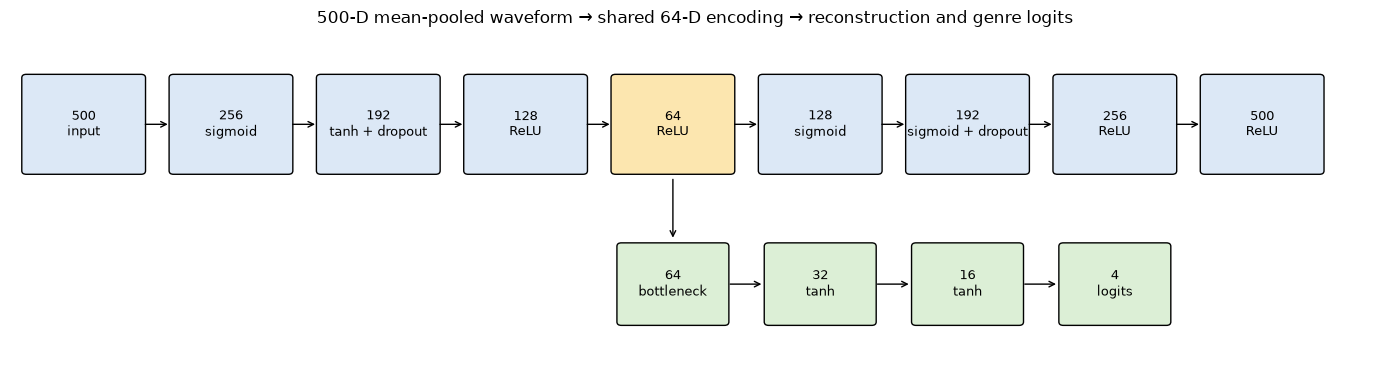

In [9]:
from matplotlib.patches import FancyBboxPatch
fig, ax = plt.subplots(figsize=(14, 4))
ax.set_xlim(-.5, 8.8); ax.set_ylim(-2, 1); ax.axis('off')
encoder_labels = ['500\ninput', '256\nsigmoid', '192\ntanh + dropout', '128\nReLU', '64\nReLU',
                  '128\nsigmoid', '192\nsigmoid + dropout', '256\nReLU', '500\nReLU']
for i, label in enumerate(encoder_labels):
    ax.add_patch(FancyBboxPatch((i-.39,-.2),.78,.8,boxstyle='round,pad=0.03',
                               facecolor='#fce6af' if i==4 else '#dce8f6'))
    ax.text(i,.2,label,ha='center',va='center',fontsize=9)
    if i<8: ax.annotate('',xy=(i+.59,.2),xytext=(i+.4,.2),arrowprops={'arrowstyle':'->'})
for xloc,label in [(4,'64\nbottleneck'),(5,'32\ntanh'),(6,'16\ntanh'),(7,'4\nlogits')]:
    ax.add_patch(FancyBboxPatch((xloc-.35,-1.5),.7,.65,boxstyle='round,pad=0.03',facecolor='#dcefd6'))
    ax.text(xloc,-1.175,label,ha='center',va='center',fontsize=9)
    if xloc<7: ax.annotate('',xy=(xloc+.62,-1.175),xytext=(xloc+.37,-1.175),arrowprops={'arrowstyle':'->'})
ax.annotate('',xy=(4,-.8),xytext=(4,-.25),arrowprops={'arrowstyle':'->'})
ax.set_title('500-D mean-pooled waveform → shared 64-D encoding → reconstruction and genre logits')
fig.tight_layout()
(RESULT_DIR/'figures').mkdir(exist_ok=True)
fig.savefig(RESULT_DIR/'figures'/'figure2_architecture.png',dpi=160)
display(fig); plt.close(fig)

### Train the complete experiment set

All schedules and objectives below are fixed before test evaluation. The primary named model is
`paper_architecture_repository_loss`: 500 epochs, keep probability 0.9, repository objective.
The two other joint runs are discrepancy diagnostics, not candidates chosen using test results.
Each run saves its final epoch and its best development checkpoint. We report both.

In [10]:
experiments = default_experiments(seed=42)
if SMOKE:
    for config in experiments: config.epochs = 2
display(pd.DataFrame([asdict(c) for c in experiments]))
models, histories, provenance = {}, {}, {}
for config in experiments:
    models[config.name], histories[config.name], provenance[config.name] = train_experiment(
        config, X, y, split, RESULT_DIR)
display(pd.DataFrame(provenance).T[['best_epoch','best_dev_score','elapsed_seconds','test_used_for_selection']])

,name,kind,epochs,keep_probability,objective,seed,learning_rate,batch_size,shuffle_each_epoch
0,baseline,baseline,200,0.9,repository,42,0.0001,512,False
1,vanilla_autoencoder,autoencoder,400,0.8,repository,42,0.0001,512,False
2,released_code_200_epochs,joint,200,0.8,repository,42,0.0001,512,False
3,paper_architecture_repository_loss,joint,500,0.9,repository,42,0.0001,512,False
4,paper_literal_equation,joint,500,0.9,paper_literal,42,0.0001,512,False


baseline: loaded completed training; test remains unused.


vanilla_autoencoder: loaded completed training; test remains unused.


released_code_200_epochs: loaded completed training; test remains unused.


paper_architecture_repository_loss: loaded completed training; test remains unused.


paper_literal_equation: loaded completed training; test remains unused.


,best_epoch,best_dev_score,elapsed_seconds,test_used_for_selection
baseline,123,0.415,10.571098,False
vanilla_autoencoder,6,-0.011096,43.258269,False
released_code_200_epochs,181,0.624,29.743197,False
paper_architecture_repository_loss,362,0.639,74.887644,False
paper_literal_equation,497,0.629,75.115335,False


### Evaluate frozen models and reproduce Table 1

This is the first full-run use of the test set. There is no retraining or threshold adjustment
in response to its accuracy. `best` means selected by development accuracy (by development MSE for
the unsupervised autoencoder); `last` means the predeclared final epoch.

In [11]:
all_rows, results = [], {}
for config in experiments:
    for checkpoint in ['best','last']:
        table, output = score_model(models[config.name], config, X, y, split, RESULT_DIR, checkpoint)
        all_rows.append(table)
        if checkpoint == 'best': results[config.name] = output
metrics = pd.concat(all_rows, ignore_index=True)
metrics.to_csv(RESULT_DIR/'all_metrics.csv', index=False)
display(metrics)

paper = pd.DataFrame({'model':['baseline','paper_architecture_repository_loss'],
                      'paper_train':[.520,.949], 'paper_dev':[.381,.641], 'paper_test':[.364,.653]})
ours = metrics[metrics.checkpoint.eq('best')].pivot(index='experiment',columns='split',values='accuracy')
comparison = paper.merge(ours, left_on='model', right_index=True)
comparison['test_difference_percentage_points'] = 100*(comparison['test']-comparison.paper_test)
comparison.to_csv(RESULT_DIR/'paper_comparison.csv',index=False)
display(comparison.style.format({c:'{:.3f}' for c in comparison.columns if c != 'model'}))
primary_test = float(ours.loc['paper_architecture_repository_loss','test'])
print(f'Measured primary test accuracy: {primary_test:.1%}; paper: 65.3%.')
print('Meets/exceeds the numerical paper reference:', primary_test >= .653)
if SMOKE: print('SOFTWARE CHECK ONLY: these two-epoch scores are not reproduction results.')

,experiment,checkpoint,split,n,loss,mse,cross_entropy,accuracy
0,baseline,best,train,6000,1.250098,0.000000,1.250098,0.523500
1,baseline,best,dev,1000,1.409317,0.000000,1.409317,0.415000
2,baseline,best,test,1000,1.408020,0.000000,1.408020,0.415000
3,baseline,last,train,6000,1.221375,0.000000,1.221375,0.529333
4,baseline,last,dev,1000,1.432620,0.000000,1.432620,0.404000
5,baseline,last,test,1000,1.423313,0.000000,1.423313,0.416000
6,vanilla_autoencoder,best,train,6000,0.011363,0.011363,0.000000,NaN
7,vanilla_autoencoder,best,dev,1000,0.011096,0.011096,0.000000,NaN
8,vanilla_autoencoder,best,test,1000,0.011260,0.011260,0.000000,NaN
9,vanilla_autoencoder,last,train,6000,0.011363,0.011363,0.000000,NaN


,model,paper_train,paper_dev,paper_test,dev,test,train,test_difference_percentage_points
0,baseline,0.520,0.381,0.364,0.415,0.415,0.523,5.100
1,paper_architecture_repository_loss,0.949,0.641,0.653,0.639,0.636,0.950,-1.700


Measured primary test accuracy: 63.6%; paper: 65.3%.
Meets/exceeds the numerical paper reference: False


### Table 2: held-out precision, recall and F1, compared by genre name

In [12]:
primary = 'paper_architecture_repository_loss'
test_truth = y[split['test']]
test_predictions = results[primary]['test']['prediction']
report = classification_report(test_truth, test_predictions, labels=range(4), target_names=GENRES,
                               output_dict=True, zero_division=0)
per_class = pd.DataFrame(report).T.loc[GENRES].reset_index(names='genre')
paper_classes = pd.DataFrame({'genre':GENRES, 'paper_precision':[.783,.606,.515,.670],
                             'paper_recall':[.775,.627,.554,.608], 'paper_f1':[.779,.616,.5337,.638]})
per_class = per_class.merge(paper_classes,on='genre')
per_class.to_csv(RESULT_DIR/'per_class_comparison.csv',index=False)
display(per_class.round(4))
print('Macro F1:', report['macro avg']['f1-score'])

,genre,precision,recall,f1-score,support,paper_precision,paper_recall,paper_f1
0,classical,0.7671,0.7375,0.7520,259.0,0.783,0.775,0.7790
1,jazz,0.5376,0.5652,0.5511,253.0,0.606,0.627,0.6160
2,metal,0.5927,0.5976,0.5951,246.0,0.515,0.554,0.5337
3,pop,0.6540,0.6405,0.6472,242.0,0.670,0.608,0.6380


Macro F1: 0.6363378907462081


### Figures 1, 3, 4, 5 and 6

PCA is fitted on training embeddings, then applied to held-out test embeddings. Genre labels
only color the points. A visually separated projection is not itself proof of style transfer
or of reconstruction quality. The plots below use the declared primary model.

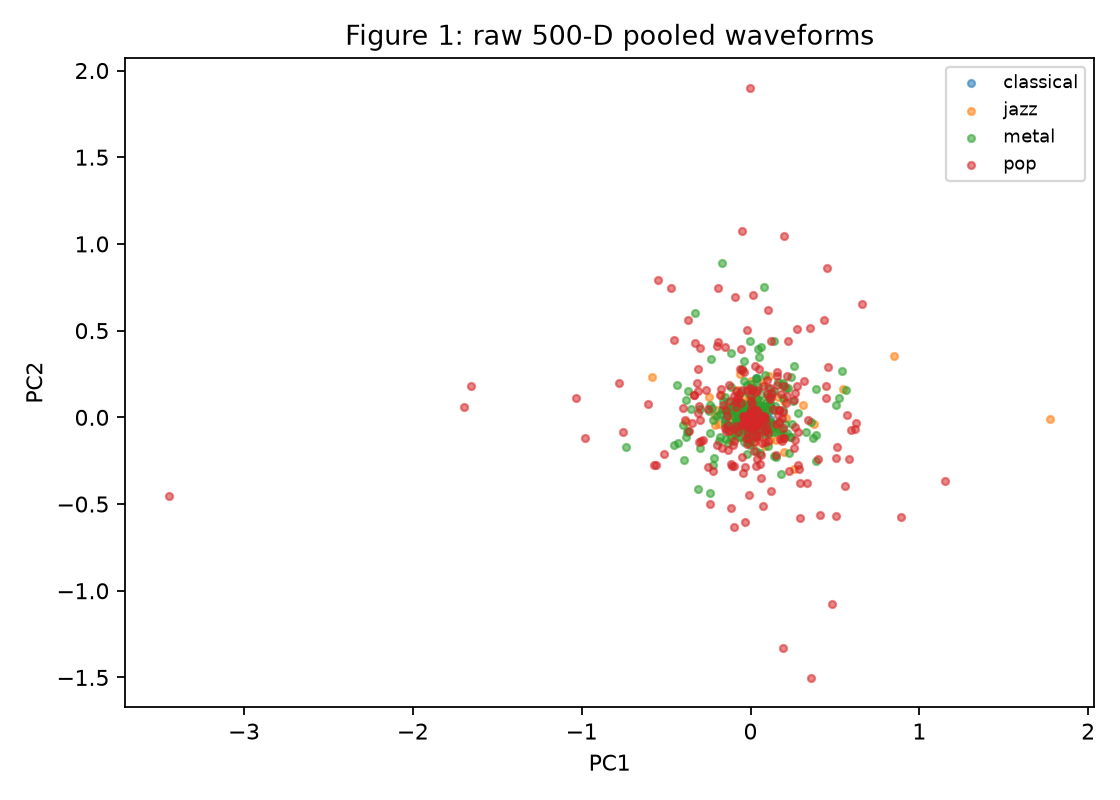

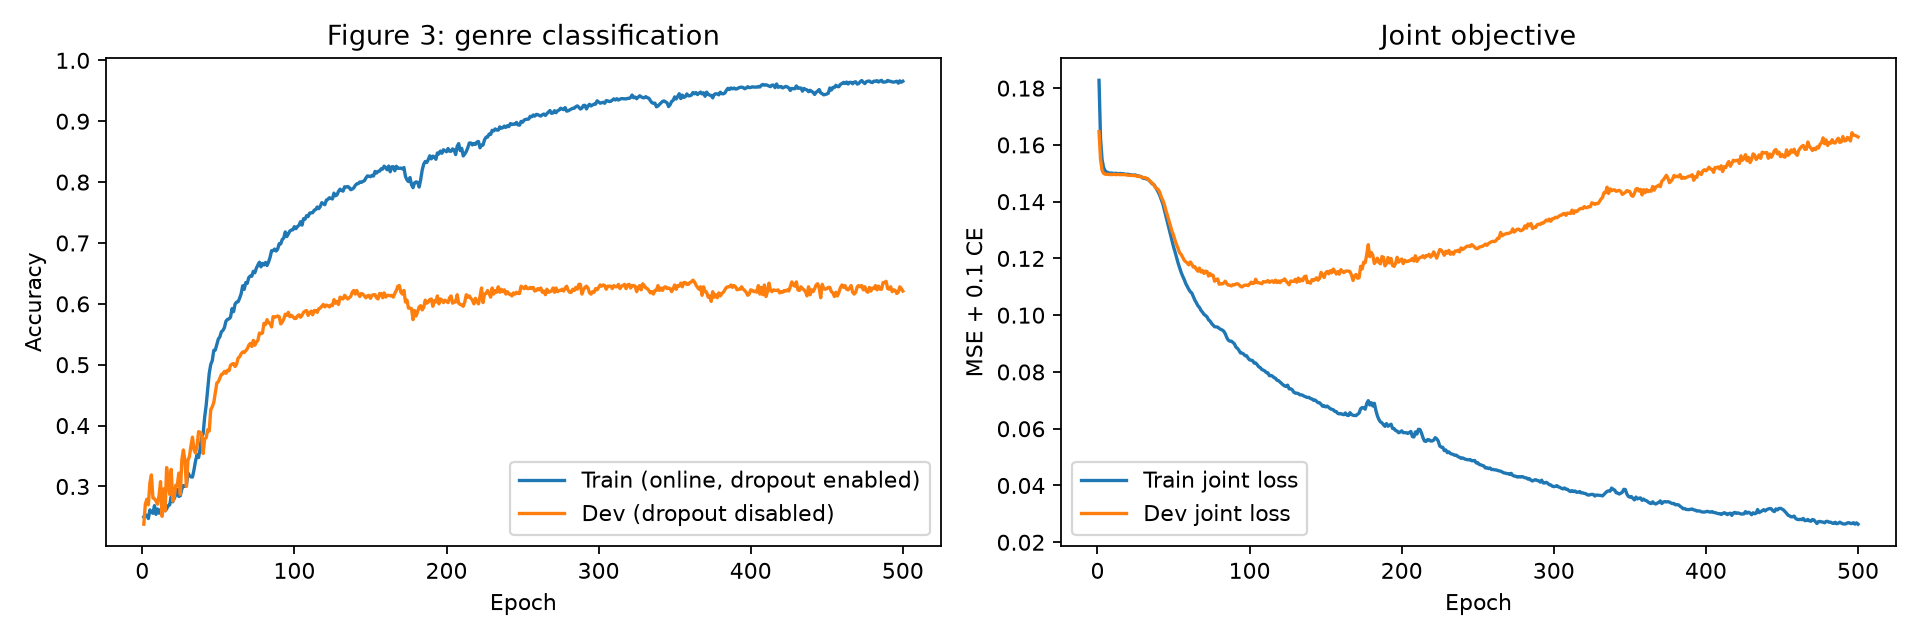

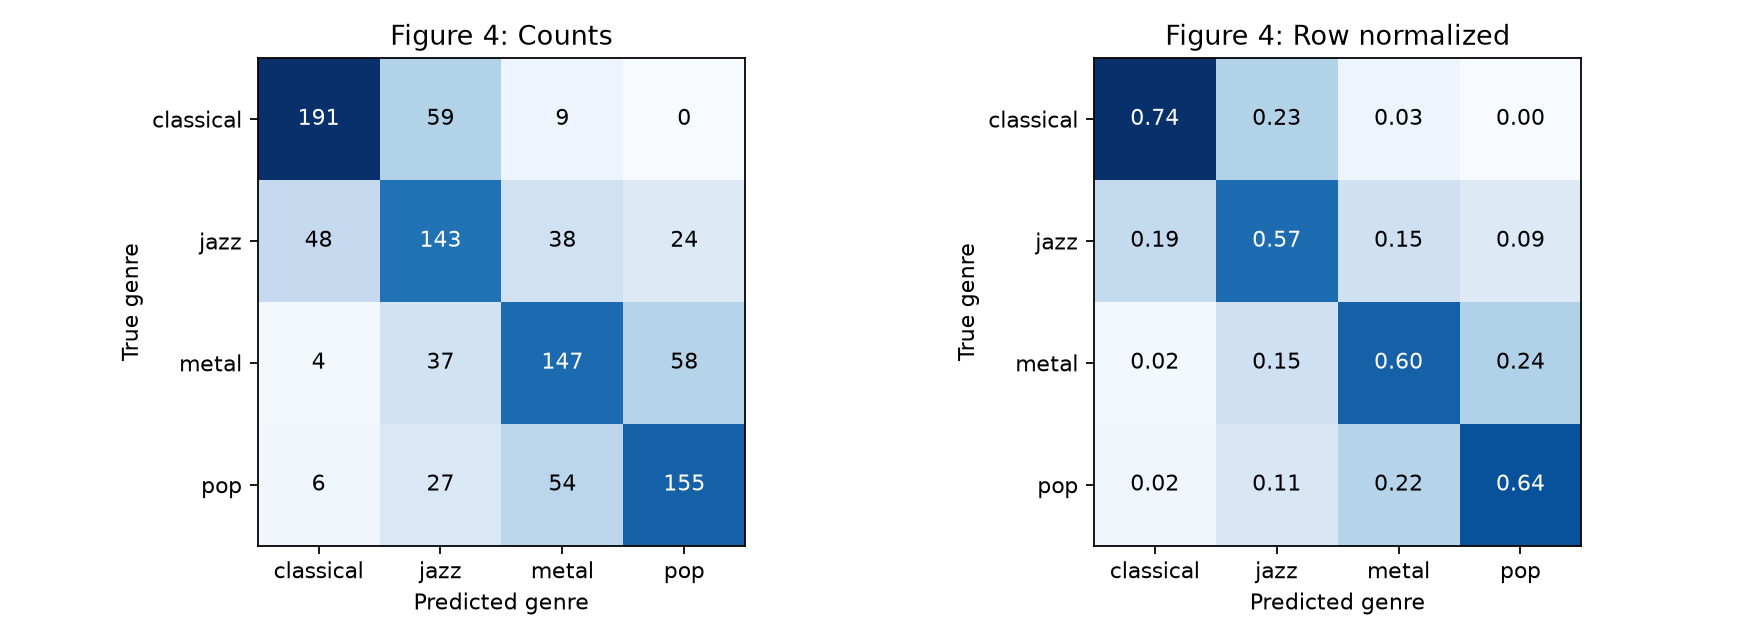

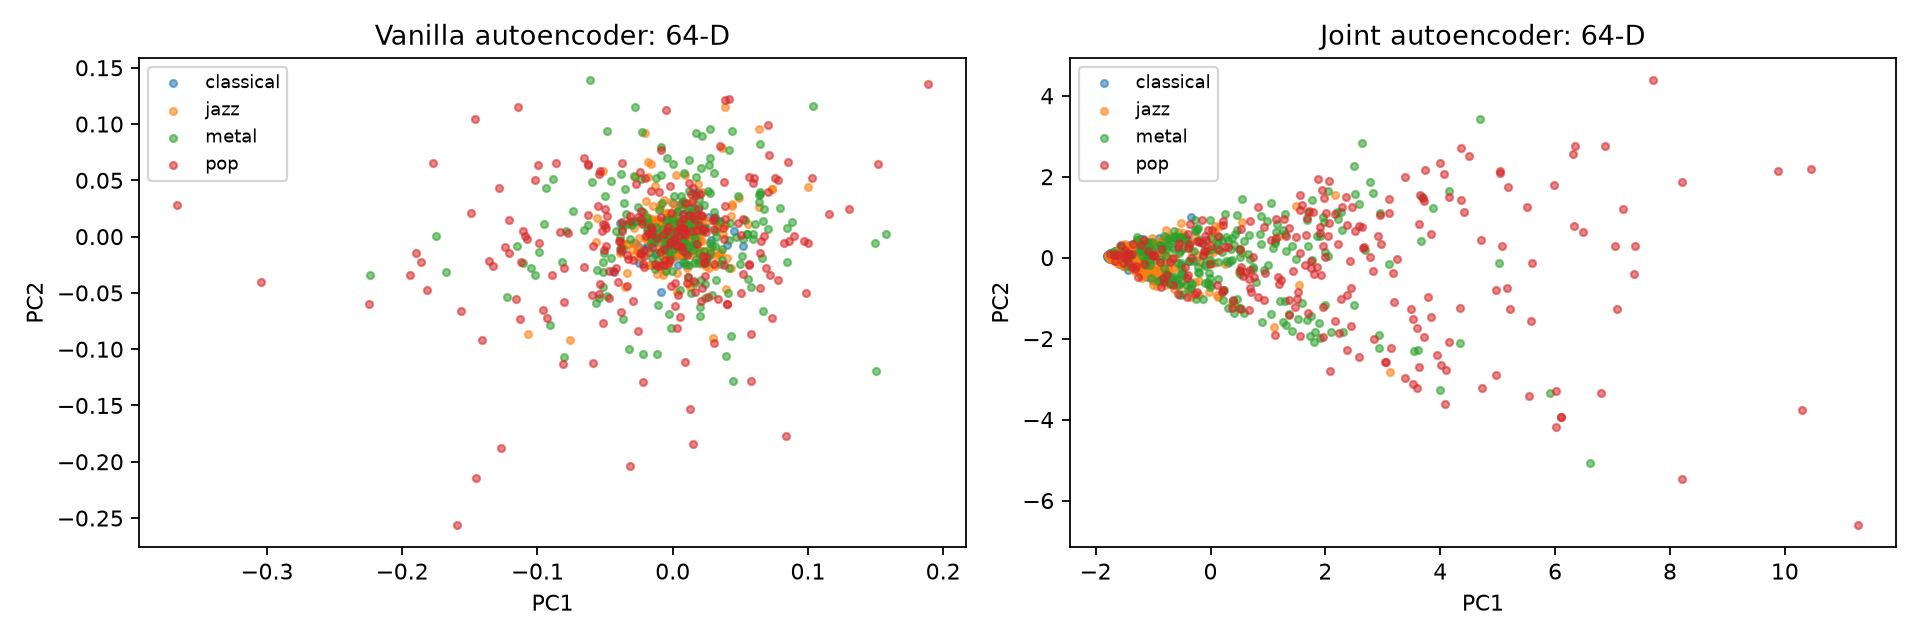

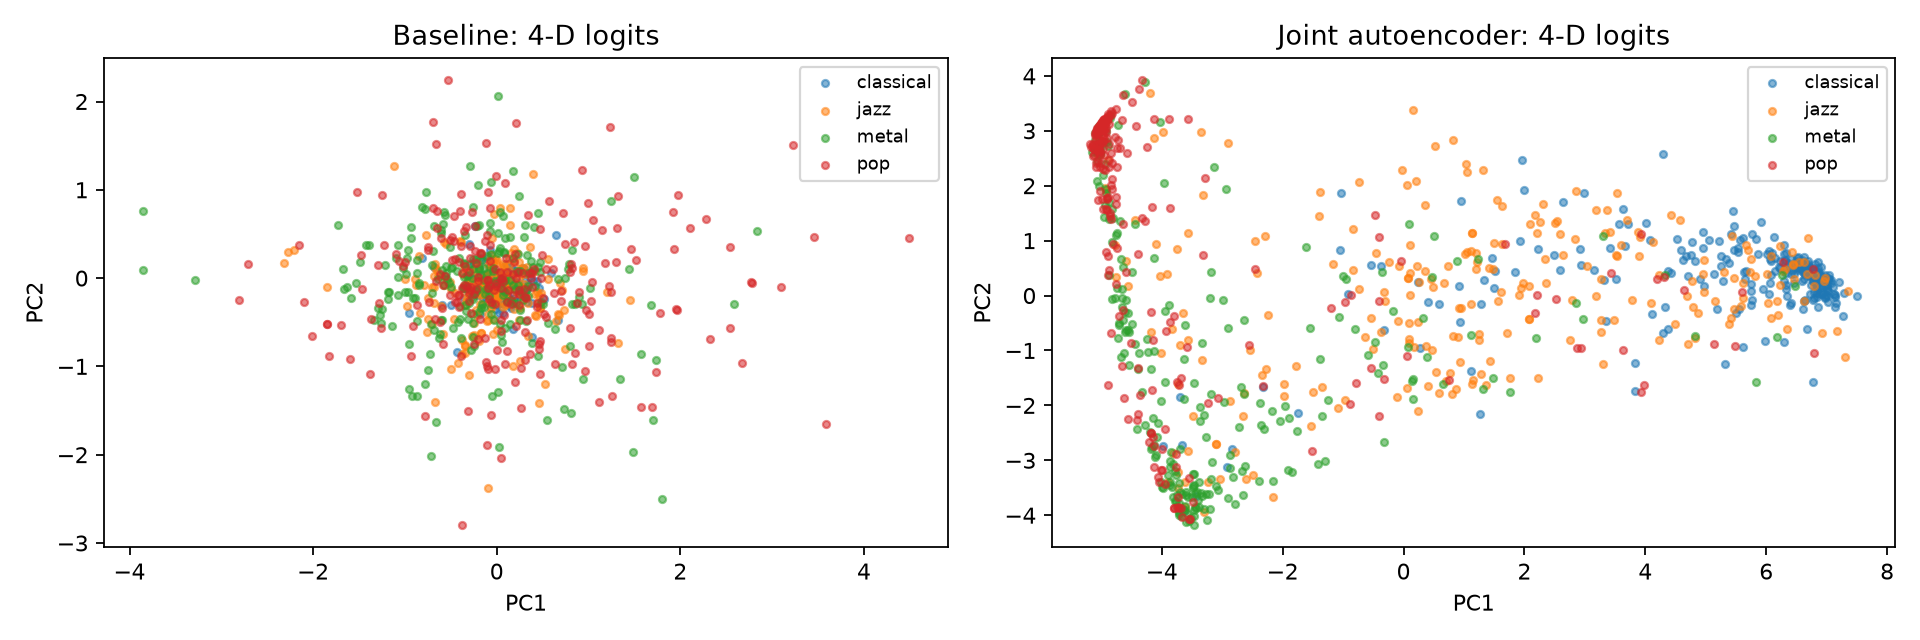

In [13]:
make_figures(X,y,split,experiments,results,histories,RESULT_DIR)
from IPython.display import Image, display
for name in ['figure1_raw_pca.png','figure3_learning_curves.png','figure4_confusion.png',
             'figure5_bottleneck_pca.png','figure6_logits_pca.png']:
    display(Image(filename=str(RESULT_DIR/'figures'/name)))

### Reconstruction sanity check

The released decoder ends in ReLU despite signed raw waveforms. Check whether it collapses
to all-zero predictions: a useful classifier alone does not establish a useful autoencoder.
The original released joint checkpoint also reconstructs zero on its saved development inputs.
This limitation is retained and reported in the faithful implementation.

{
  "sampled_test_examples": 16,
  "nonzero_reconstructed_values": 0,
  "test_reconstruction_mse": 0.011259868741035461,
  "zero_predictor_test_mse": 0.011259868741035461
}


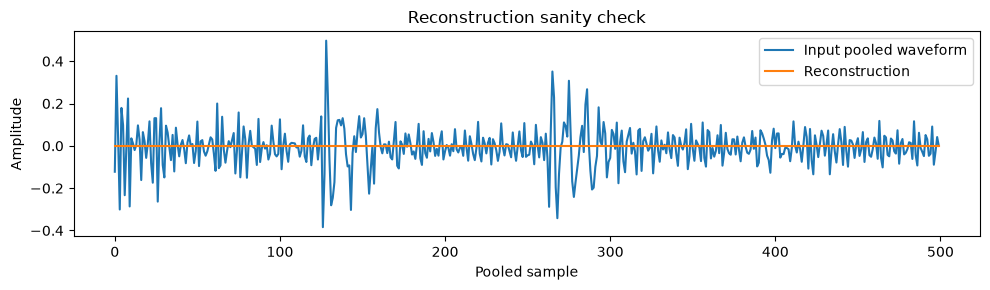

In [14]:
config = next(c for c in experiments if c.name == primary)
model = models[primary]
model.load_state_dict(torch.load(RESULT_DIR/primary/'best.pt',map_location=DEVICE,weights_only=True))
model.eval()
with torch.no_grad():
    out = model(torch.as_tensor(X[split['test'][:16]],device=DEVICE))
recon = out['reconstruction'].cpu().numpy()
reconstruction_audit = {'sampled_test_examples':16,
    'nonzero_reconstructed_values':int(np.count_nonzero(recon)),
    'test_reconstruction_mse':float(results[primary]['test']['metrics']['mse']),
    'zero_predictor_test_mse':float(np.mean(X[split['test']]**2))}
(RESULT_DIR/'reconstruction_audit.json').write_text(json.dumps(reconstruction_audit,indent=2))
print(json.dumps(reconstruction_audit,indent=2))
fig,ax=plt.subplots(figsize=(10,3))
ax.plot(X[split['test'][0]],label='Input pooled waveform')
ax.plot(recon[0],label='Reconstruction')
ax.set(xlabel='Pooled sample',ylabel='Amplitude',title='Reconstruction sanity check'); ax.legend()
fig.tight_layout();fig.savefig(RESULT_DIR/'figures'/'reconstruction_check.png',dpi=160)
display(fig);plt.close(fig)

### Initialization robustness: report every predeclared seed

Seeds 42, 43 and 44 use the **same** train/dev/test membership. Each uses the same 500-epoch
schedule and selects its checkpoint using development data only. These runs measure initialization
sensitivity; the highest test seed is never substituted for the primary seed-42 result.

In [15]:
seed_dir = WORK_DIR/'results'/'seed_robustness'
seed_dir.mkdir(parents=True,exist_ok=True)
robustness_rows = []
if RUN_SEED_ROBUSTNESS and not SMOKE:
    seed_models = []
    for init_seed in [43,44]:
        config = Experiment(f'joint_seed_{init_seed}','joint',500,seed=init_seed)
        model, _, _ = train_experiment(config,X,y,split,seed_dir)
        seed_models.append((config,model))
    for config,model in seed_models:
        for checkpoint in ['best','last']:
            table,_ = score_model(model,config,X,y,split,seed_dir,checkpoint)
            robustness_rows.append(table)
    extra_seed_metrics = pd.concat(robustness_rows,ignore_index=True)
    extra_seed_metrics.to_csv(seed_dir/'all_metrics.csv',index=False)
    primary_seed = metrics[metrics.experiment.eq(primary)].copy()
    primary_seed['experiment'] = 'joint_seed_42'
    seed_metrics = pd.concat([primary_seed,extra_seed_metrics],ignore_index=True)
    seed_tests = seed_metrics[seed_metrics.checkpoint.eq('best') & seed_metrics.split.eq('test')]
    display(seed_tests[['experiment','accuracy']])
    print(f'Test accuracy mean: {seed_tests.accuracy.mean():.2%}; sample SD: {seed_tests.accuracy.std(ddof=1):.2%}')
    seed_metrics.to_csv(RESULT_DIR/'three_seed_metrics.csv',index=False)

joint_seed_43: loaded completed training; test remains unused.


joint_seed_44: loaded completed training; test remains unused.


,experiment,accuracy
2,joint_seed_42,0.636
8,joint_seed_43,0.620
14,joint_seed_44,0.624


Test accuracy mean: 62.67%; sample SD: 0.83%


### Separate improvement: equal-probability ensemble

This extension averages the softmax probabilities of the three fixed seeds above, with weights
1/3 each. It adds no new training data or feature engineering. Each member checkpoint was selected
by development accuracy. It is **not the paper's single-model experiment**.

The ensemble was added after inspecting individual-run results, so it is an exploratory improvement
on this existing held-out split, not a new independent confirmation test. No ensemble weights,
temperature or thresholds are fitted to test data. Its result is reported separately from the
primary single-model comparison, with member checkpoint hashes and all test predictions saved.

In [16]:
def evaluate_ensemble(X,y,split,work_dir=Path('.')):
    work_dir=Path(work_dir)
    members=[work_dir/'results'/'source_grounded'/'paper_architecture_repository_loss'/'best.pt',
             work_dir/'results'/'seed_robustness'/'joint_seed_43'/'best.pt',
             work_dir/'results'/'seed_robustness'/'joint_seed_44'/'best.pt']
    result_dir=work_dir/'results'/'ensemble_extension'
    result_dir.mkdir(parents=True,exist_ok=True)
    accumulated={k:np.zeros((len(indices),4),dtype=np.float64) for k,indices in split.items()}
    for path in members:
        model=Autoencoder(joint=True,keep_probability=.9).to(DEVICE)
        model.load_state_dict(torch.load(path,map_location=DEVICE,weights_only=True))
        for name,indices in split.items():
            result=evaluate(model,torch.as_tensor(X[indices],device=DEVICE),
                              torch.as_tensor(y[indices],device=DEVICE))
            # Use softmax probabilities, not votes or a test-fitted mixing rule.
            scores=result['logits'].astype(np.float64)
            scores-=scores.max(axis=1,keepdims=True)
            probabilities=np.exp(scores)
            probabilities/=probabilities.sum(axis=1,keepdims=True)
            accumulated[name]+=probabilities/len(members)
    rows=[]
    for name,indices in split.items():
        probabilities=accumulated[name]
        predictions=probabilities.argmax(axis=1)
        rows.append({'experiment':'equal_probability_ensemble_3_seeds','split':name,
                     'n':len(indices),'accuracy':accuracy_score(y[indices],predictions)})
        table=pd.DataFrame({'row':indices,'truth':y[indices],'prediction':predictions})
        for j,genre in enumerate(GENRES):table['probability_'+genre]=probabilities[:,j]
        table.to_csv(result_dir/f'{name}_predictions.csv',index=False)
        report=classification_report(y[indices],predictions,labels=range(4),target_names=GENRES,
                                     output_dict=True,zero_division=0)
        (result_dir/f'{name}_classification.json').write_text(json.dumps(report,indent=2))
    metrics=pd.DataFrame(rows)
    metrics.to_csv(result_dir/'metrics.csv',index=False)
    (result_dir/'protocol.json').write_text(json.dumps({
        'kind':'separate exploratory extension, not exact single-model reproduction',
        'combination':'arithmetic mean of softmax probabilities','weights':[1/3]*3,
        'seeds':[42,43,44],'members':[{'path':str(p),'sha256':sha256(p)} for p in members],
        'selection':'each member selected on development accuracy only',
        'test_fitted_weights':False,'note':'Added after inspecting the individual-run results; no new independent test set.'},indent=2))
    return metrics

In [17]:
if RUN_SEED_ROBUSTNESS and not SMOKE:
    ensemble_metrics=evaluate_ensemble(X,y,split,WORK_DIR)
    display(ensemble_metrics)
    ensemble_test=float(ensemble_metrics.loc[ensemble_metrics.split.eq('test'),'accuracy'].iloc[0])
    print(f'Ensemble test accuracy: {ensemble_test:.1%}; paper single model: 65.3%.')
    print('This ensemble meets/exceeds the numerical reference:',ensemble_test >= .653)

,experiment,split,n,accuracy
0,equal_probability_ensemble_3_seeds,train,6000,0.940833
1,equal_probability_ensemble_3_seeds,dev,1000,0.648000
2,equal_probability_ensemble_3_seeds,test,1000,0.658000


Ensemble test accuracy: 65.8%; paper single model: 65.3%.
This ensemble meets/exceeds the numerical reference: True


### Separate song-disjoint generalization audit

The paper's segment split lets portions of the same recording appear on both sides of the split.
The earlier manifest quantifies this overlap. Here we hold entire songs apart and keep the
6,000/1,000/1,000 example counts. The exact same baseline and joint schedules are used.
This is a distinct task, so its scores are not substituted into the paper comparison.
Song-disjoint splitting does not remove GTZAN's cross-file duplicates or artist overlap.

In [18]:
if RUN_SONG_DISJOINT and not SMOKE:
    disjoint_dir=WORK_DIR/'results'/'song_disjoint'
    disjoint_dir.mkdir(parents=True,exist_ok=True)
    disjoint_split=make_split(y,manifest,disjoint_dir,seed=42,song_disjoint=True)
    disjoint_configs=[c for c in default_experiments() if c.name in ['baseline',primary]]
    disjoint_models=[]
    for config in disjoint_configs:
        model,_,_=train_experiment(config,X,y,disjoint_split,disjoint_dir)
        disjoint_models.append((config,model))
    tables=[]
    for config,model in disjoint_models:
        for checkpoint in ['best','last']:
            table,_=score_model(model,config,X,y,disjoint_split,disjoint_dir,checkpoint)
            tables.append(table)
    disjoint_metrics=pd.concat(tables,ignore_index=True)
    disjoint_metrics.to_csv(disjoint_dir/'all_metrics.csv',index=False)
    display(disjoint_metrics)

{
  "seed": 42,
  "protocol": "song_disjoint",
  "overlapping_songs": {
    "train_dev": 0,
    "train_test": 0,
    "dev_test": 0
  },
  "class_counts": {
    "train": [
      1500,
      1500,
      1500,
      1500
    ],
    "dev": [
      240,
      260,
      240,
      260
    ],
    "test": [
      260,
      240,
      260,
      240
    ]
  }
}
baseline: loaded completed training; test remains unused.


paper_architecture_repository_loss: loaded completed training; test remains unused.

,experiment,checkpoint,split,n,loss,mse,cross_entropy,accuracy
0,baseline,best,train,6000,1.257694,0.000000,1.257694,0.527167
1,baseline,best,dev,1000,1.418544,0.000000,1.418544,0.444000
2,baseline,best,test,1000,1.463634,0.000000,1.463634,0.388000
3,baseline,last,train,6000,1.195697,0.000000,1.195697,0.534000
4,baseline,last,dev,1000,1.472878,0.000000,1.472878,0.425000
5,baseline,last,test,1000,1.573219,0.000000,1.573219,0.374000
6,paper_architecture_repository_loss,best,train,6000,0.026288,0.011353,0.149353,0.965167
7,paper_architecture_repository_loss,best,dev,1000,0.168670,0.012503,1.561675,0.613000
8,paper_architecture_repository_loss,best,test,1000,0.173963,0.009912,1.640514,0.592000
9,paper_architecture_repository_loss,last,train,6000,0.028050,0.011353,0.166968,0.954833


### Source validation artifacts and conclusions

The accompanying `validate_reproduction.py` uses the original repository's actual TensorFlow
function bodies to compare pooled inputs, forward activations, objective values, gradients and
ten Adam updates against this port. TensorFlow is optional for training this notebook; rerunning
that audit requires the repository and TensorFlow 2.20's compatibility API.

Interpret the outcome in two parts: whether genre classification approaches 65.3%, and whether
the claimed reconstruction/embedding behavior survives inspection. Preserve weaker runs and
the literal-equation result. Do not call a changed objective or a different held-out split an
exact numerical replication. A higher score on this random segment split is not evidence of
better generalization to unseen songs or of musical style transfer.

In [19]:
for path in [WORK_DIR/'analysis'/'numerical_validation.json',
             WORK_DIR/'analysis'/'reference_checkpoint_audit.json']:
    if path.exists():
        print(path.name)
        print(path.read_text())
print('All metrics:',RESULT_DIR/'all_metrics.csv')
print('Per-class comparison:',RESULT_DIR/'per_class_comparison.csv')
print('Data and split provenance:',RESULT_DIR/'segments.csv')
print('Figures:',RESULT_DIR/'figures')
print('Final statement:', f"{primary_test:.1%} measured test accuracy versus the paper's 65.3%.")

numerical_validation.json
{
  "source_commit": "00b1802e24d1ab6fb3135b24a44976a51033ed24",
  "checks": {
    "original_tf1_forward_gradient_adam": {
      "encoding": 8.493661880493164e-07,
      "reconstruction": 0.0,
      "logits": 5.334615707397461e-06,
      "loss": 0.0,
      "gradient_max_absolute_error": 4.470348358154297e-08,
      "ten_adam_updates_max_absolute_error": 3.5762786865234375e-07
    },
    "classical_pooling_max_error": 0.0,
    "jazz_pooling_max_error": 0.0,
    "metal_pooling_max_error": 0.0,
    "pop_pooling_max_error": 0.0,
    "repository_formula": true,
    "paper_literal_formula": true
  },
  "passed": true
}
reference_checkpoint_audit.json
{
  "csv_rows": 2000,
  "matching_pooled_inputs": 1996,
  "matching_label_agreement": 1.0,
  "unmatched_rows": [
    178,
    729,
    1281,
    1456
  ],
  "interpretation": "Historical development-set diagnostic; not independent test performance.",
  "baseline_released_checkpoint_saved_dev_accuracy": 0.4585,
  "joint_